# 03 · Modelado con ML tradicional

**Fase 4 de CRISP-DM.** Líneas base y tres modelos sobre el vector de características φ(x) ∈ ℝ⁶⁸
(notebook 02, §6). Este notebook **lee los resultados guardados**; para regenerarlos:

```bash
python -m src.training.train --model classic    # GridSearchCV → experiments/results/classic.json, cv_*.csv
python -m src.evaluation.ablation               # → experiments/results/ablacion_svm.json
```

Protocolo: se ajusta con `train` (validación cruzada de 5 pliegues **por grupo**), se compara con
`val`; `test` y las fotos propias no se usan hasta la Fase 5. Métrica principal: **F1-macro**.
Pesos por muestra = 1/tamaño del grupo, con las tres clases equilibradas. Detalle en
`docs/crisp-dm.md` §4.1.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src import config  # noqa: E402
from src.models.classic_ml import build_models  # noqa: E402

pd.set_option("display.precision", 3)
classic = json.load(open(config.RESULTS_DIR / "classic.json", encoding="utf-8"))
NAMES = {"mayoria": "Mayoría", "azar_estratificado": "Azar estratificado",
         "regresion_logistica": "Regresión logística", "svm": "SVM (RBF)", "random_forest": "Random Forest"}

## 1. Modelos y rejillas de hiperparámetros

Cada modelo es un pipeline `StandardScaler → clasificador`, así la estandarización se estima solo
con los datos de entrenamiento de cada pliegue.

In [2]:
pd.DataFrame([{"modelo": NAMES[k], "clasificador": type(est.named_steps["clf"]).__name__,
               "rejilla": {p.removeprefix("clf__"): v for p, v in grid.items()},
               "combinaciones": int(np.prod([len(v) for v in grid.values()]))}
              for k, (est, grid) in build_models().items()])

,modelo,clasificador,rejilla,combinaciones
0,Regresión logística,LogisticRegression,"{'C': ['0.01', '0.1', 1, 10, 100]}",5
1,SVM (RBF),SVC,"{'C': [1, 10, 100], 'gamma': ['scale', '0.03',...",9
2,Random Forest,RandomForestClassifier,"{'max_depth': [None, 12, 20], 'min_samples_lea...",12


### Pesos por muestra (desbalanceo y copias)

Peso = 1/tamaño del grupo, reescalado para que las tres clases sumen lo mismo
(`sample_weights`, `src/training/train.py`). Así 30 copias de una foto cuentan como una, y
Defectuosa/Podrida pesan tanto como Buena aunque tengan ~5× menos imágenes.

In [3]:
from src.features.extract_features import load_features  # noqa: E402
from src.training.train import sample_weights  # noqa: E402

_, rows_tr = load_features("train")
w = pd.DataFrame({"calidad": [r["calidad"] for r in rows_tr], "fuente": [r["fuente"] for r in rows_tr],
                  "peso": sample_weights(rows_tr)})
w.groupby("calidad").agg(imagenes=("peso", "size"), peso_total=("peso", "sum"), peso_medio=("peso", "mean"))

,imagenes,peso_total,peso_medio
calidad,,,
Buena,8577,4098.333,0.478
Defectuosa,1865,4098.333,2.197
Podrida,1853,4098.333,2.212


## 2. Resultados

In [4]:
summary = pd.DataFrame([{
    "modelo": NAMES[k],
    "mejores hiperparámetros": {p.removeprefix("clf__"): v for p, v in r.get("mejores_hiperparametros", {}).items()} or "—",
    "F1 CV": r.get("f1_macro_cv"), "± CV": r.get("f1_macro_cv_std"),
    "F1 train": r.get("train", {}).get("f1_macro"),
    "F1 val": r["val"]["f1_macro"], "exactitud val": r["val"]["accuracy"],
    "F1 val Kaggle": r["val"]["por_fuente"].get("kaggle"), "F1 val HDF": r["val"]["por_fuente"].get("hdf"),
} for k, r in classic.items()])
summary

,modelo,mejores hiperparámetros,F1 CV,± CV,F1 train,F1 val,exactitud val,F1 val Kaggle,F1 val HDF
0,Mayoría,—,NaN,NaN,NaN,0.273,0.692,0.317,0.204
1,Azar estratificado,—,NaN,NaN,NaN,0.339,0.535,0.312,0.314
2,Regresión logística,{'C': 1},0.759,0.057,0.767,0.757,0.806,0.615,0.704
3,SVM (RBF),"{'C': 100, 'gamma': 'scale'}",0.887,0.011,1.000,0.842,0.877,0.791,0.790
4,Random Forest,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.859,0.059,0.949,0.839,0.874,0.804,0.791


- La regresión logística (frontera lineal) queda muy por debajo de SVM y Random Forest: la
  separación entre clases en φ(x) no es lineal.
- SVM y Random Forest empatan en validación (0,84); el SVM es más estable entre pliegues (± 0,01).
- F1 train ≫ F1 val en SVM/RF → sobreajuste, acotado por la validación cruzada por grupos.

### Por clase (validación)

In [5]:
per_class = pd.concat({NAMES[k]: pd.DataFrame(r["val"]["por_clase"]).T
                       for k, r in classic.items() if k in ("regresion_logistica", "svm", "random_forest")})
per_class

precision  recall     f1
Regresión logística Buena           0.965   0.796  0.873
                    Defectuosa      0.572   0.792  0.664
                    Podrida         0.628   0.884  0.734
SVM (RBF)           Buena           0.957   0.892  0.923
                    Defectuosa      0.670   0.793  0.727
                    Podrida         0.833   0.921  0.875
Random Forest       Buena           0.929   0.908  0.918
                    Defectuosa      0.685   0.714  0.699
                    Podrida         0.872   0.929  0.900

Meta de negocio (§1.4): **recall de Podrida ≥ 0,90** (no dejar pasar fruta podrida como buena) y
F1-macro ≥ 0,85.

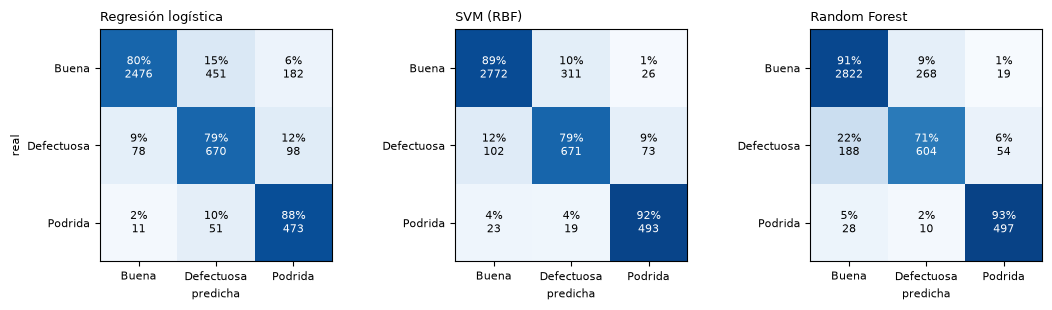

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, k in zip(axes, ["regresion_logistica", "svm", "random_forest"]):
    cm = np.array(classic[k]["val"]["matriz_confusion"])
    frac = cm / cm.sum(1, keepdims=True)
    ax.imshow(frac, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{frac[i, j]:.0%}\n{cm[i, j]}", ha="center", va="center", fontsize=8,
                    color="white" if frac[i, j] > 0.55 else "black")
    ax.set_xticks(range(3), config.QUALITY_CLASSES, fontsize=8)
    ax.set_yticks(range(3), config.QUALITY_CLASSES, fontsize=8)
    ax.set_title(NAMES[k], fontsize=9, loc="left")
    ax.set_xlabel("predicha", fontsize=8)
axes[0].set_ylabel("real", fontsize=8)
plt.tight_layout()

## 3. Ajuste de hiperparámetros

F1-macro de validación cruzada (media de 5 pliegues por grupo) para cada combinación. La brecha con
el F1 de entrenamiento muestra el sobreajuste de cada configuración.

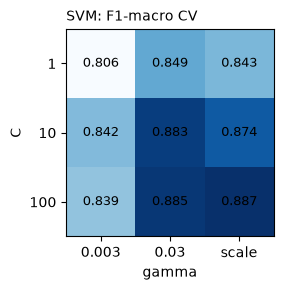

In [7]:
cv = pd.read_csv(config.RESULTS_DIR / "cv_svm.csv")
heat = cv.pivot(index="param_clf__C", columns="param_clf__gamma", values="mean_test_score")
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.imshow(heat, cmap="Blues")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.iloc[i, j]:.3f}", ha="center", va="center", fontsize=9)
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index)
ax.set_xlabel("gamma")
ax.set_ylabel("C")
ax.set_title("SVM: F1-macro CV", loc="left", fontsize=10)
plt.tight_layout()

In [8]:
for name in ["regresion_logistica", "random_forest"]:
    cv = pd.read_csv(config.RESULTS_DIR / f"cv_{name}.csv")
    cols = [c for c in cv.columns if c.startswith("param_")]
    display(cv[cols + ["mean_test_score", "std_test_score", "mean_train_score", "rank_test_score"]]  # noqa: F821
            .rename(columns=lambda c: c.removeprefix("param_clf__"))
            .sort_values("rank_test_score").head(6).assign(modelo=NAMES[name]))

,C,mean_test_score,std_test_score,mean_train_score,rank_test_score,modelo
2,1.00,0.759,0.057,0.767,1,Regresión logística
3,10.00,0.758,0.061,0.769,2,Regresión logística
4,100.00,0.757,0.059,0.769,3,Regresión logística
1,0.10,0.754,0.056,0.761,4,Regresión logística
0,0.01,0.740,0.054,0.748,5,Regresión logística


,max_depth,max_features,min_samples_leaf,mean_test_score,std_test_score,mean_train_score,rank_test_score,modelo
0,NaN,sqrt,1,0.859,0.059,0.945,1,Random Forest
8,20.0,sqrt,1,0.856,0.058,0.945,2,Random Forest
10,20.0,0.3,1,0.845,0.055,0.941,3,Random Forest
2,NaN,0.3,1,0.845,0.056,0.942,4,Random Forest
4,12.0,sqrt,1,0.843,0.058,0.925,5,Random Forest
6,12.0,0.3,1,0.838,0.050,0.928,6,Random Forest


## 4. ¿Qué características usa el modelo?

**Ablación** (SVM con los mejores hiperparámetros, entrenado solo con algunos grupos de
características) e **importancia** en Random Forest (disminución media de impureza).

In [9]:
abl = json.load(open(config.RESULTS_DIR / "ablacion_svm.json", encoding="utf-8"))
pd.Series(abl["ablacion"], name="F1 val").to_frame()

,F1 val
color,0.748
textura,0.741
forma,0.558
color+textura,0.819
color+textura+forma,0.842


{'color': 0.611, 'forma': 0.15, 'textura': 0.238}


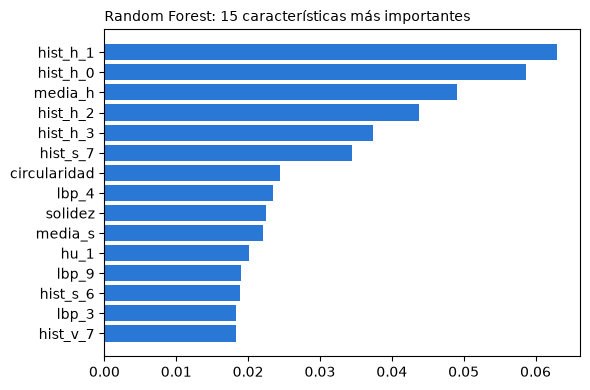

In [10]:
import joblib  # noqa: E402

from src.features.extract_features import FEATURE_GROUPS, feature_names  # noqa: E402

rf = joblib.load(config.CHECKPOINTS_DIR / "random_forest.joblib").named_steps["clf"]
imp = pd.Series(rf.feature_importances_, index=feature_names())
group = np.repeat(list(FEATURE_GROUPS), list(FEATURE_GROUPS.values()))
print(imp.groupby(group).sum().round(3).to_dict())

top = imp.sort_values().tail(15)
plt.figure(figsize=(6, 4))
plt.barh(top.index, top.values, color="#2a78d6")
plt.title("Random Forest: 15 características más importantes", loc="left", fontsize=10)
plt.tight_layout()

## 5. Generalización entre fuentes

SVM entrenado con **una sola** fuente y validado en cada una. Si el modelo aprendiera "calidad" en
general, debería funcionar razonablemente en la otra fuente.

In [11]:
cross = pd.Series(abl["entre_fuentes"])
cross.index = pd.MultiIndex.from_tuples([tuple(k.split("→")) for k in cross.index], names=["entrena", "valida"])
cross.unstack()

valida,hdf,kaggle
entrena,,
hdf,0.793,0.058
kaggle,0.424,0.786


Un modelo entrenado con una fuente casi no sirve en la otra: cada dataset tiene su propio "aspecto"
(frutas, cámaras, luz, criterio de etiquetado). El modelo conjunto funciona en ambas, pero esto
anticipa que el desempeño con las **fotos propias** puede ser menor que en validación; por eso son
la evaluación que más importa (Fase 5).